# 1. Simple Linear Regression (FICO only)

One input, one straight line: `int.rate = theta0 + theta1 * fico`. FICO is the feature most correlated
with the interest rate, so it is the natural single predictor. Fitted by **gradient descent** on the
standardised FICO score (learning rate 0.1, 2,000 steps).

From-scratch code: `RegressionAlgorithms/LinearRegression.py` (`LinearRegressionScratch`)

Charts: `Images/Regression/01_Simple_Linear_Regression/` · tables: `Results/Regression/01_Simple_Linear_Regression/`

## 1. Setup and data

In [1]:
# Setup: imports, data and the fixed 80/20 train/test split (seed 42)
import os
import sys

sys.path.insert(0, os.path.abspath(os.path.join("..", "..", "Common")))

from project import Outputs, regression_data
from model_zoo import RegressionPipeline, check_settings
from report_regression import report_regressor
from LinearRegression import LinearRegressionScratch
from sklearn.linear_model import LinearRegression

out = Outputs("Regression", "01_Simple_Linear_Regression")
d = regression_data()
print(f"train {d.X_train.shape} | test {d.X_test.shape} | target int.rate | {len(d.feature_cols)} features")

train (7662, 20) | test (1916, 20) | target int.rate | 20 features


## 2. Model

In [2]:
# Model: standardise fico (scaler fitted on train only) -> gradient-descent linear regression
model = RegressionPipeline(LinearRegressionScratch(learning_rate=0.1, n_iterations=2000), columns=["fico"])
check_settings("1. Simple Linear (FICO)", model)
model.fit(d.X_train, d.y_train, d.feature_cols)
print(f"int.rate = {model.model.intercept_:.5f} + {model.model.coef_[0]:.5f} * z(fico)")

# verification: scikit-learn's closed-form least squares on the same column
fico = d.feature_cols.index("fico")
sk = LinearRegression().fit(d.X_train[:, [fico]], d.y_train)
sk_r2 = sk.score(d.X_test[:, [fico]], d.y_test)

settings match Common/model_zoo.py (6 values checked)


int.rate = 0.12245 + -0.01927 * z(fico)


## 3. Results

Train loss (MSE)    0.000357
Test loss (MSE)     0.000334
Test RMSE           0.018269
Test MAE            0.013871
Test R2             0.515213
scikit-learn R2     0.515213
Difference         -0.000000

scratch vs scikit-learn LinearRegression: R2 0.5152 vs 0.5152 (difference -0.0000)


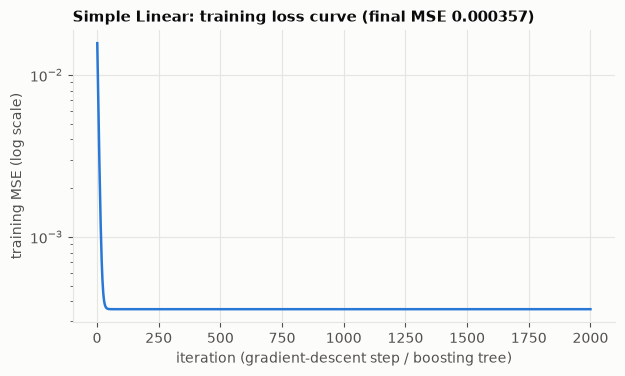

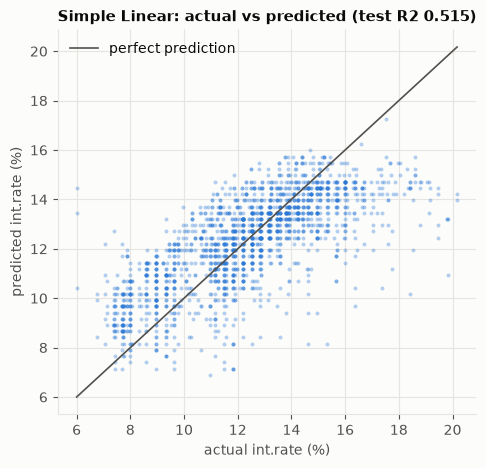

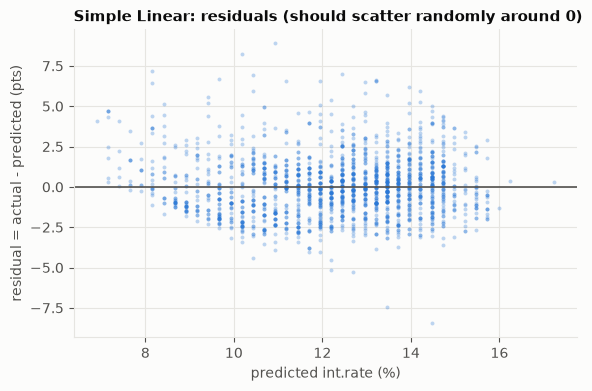

saved + reloaded TrainedModels/Regression/01_Simple_Linear_Regression.joblib (identical predictions: True)


In [3]:
# Results: metrics, loss curve, actual vs predicted, residuals, saved model
row = report_regressor(
    out, "1. Simple Linear (FICO)", model, d, model.model.loss_history, (sk_r2, "scikit-learn LinearRegression")
)